# 03 · Ringkasan EX-1 (One-to-One) · TS2Vec · RE1, RE2, RE3

Notebook ini merangkum EX-1 di tiga dataset. Detail per dataset ada di `02_ex1_<RE>_ts2vec.ipynb`.

**Setting:** pre-training TS2Vec di split train dataset S, fine-tuning lokalisasi root service di S, lalu evaluasi di split test S. Split 60/20/20 terstratifikasi, dengan 3 seed. Pembandingnya:
- **heuristik**: ranking |z| pasca-injeksi;
- **scratch**: encoder acak tanpa pre-training, dengan fine-tuning yang identik.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT / "src"))
from ssl_rcl.finetune import summarize_ranks
plt.rcParams["figure.dpi"] = 110

rows = []
for S in ["RE1", "RE2", "RE3"]:
    R = ROOT / "results" / "ex1" / f"{S}_ts2vec"
    s = pd.read_csv(R / "summary.csv")
    for (v, m), g in s.groupby(["variant", "mode"]):
        rows.append(dict(source=S, model=f"{v}-{m}", n_test=int(g["n"].iloc[0]),
                         AC1_mean=g["AC@1"].mean(), AC1_std=g["AC@1"].std(), AC3_mean=g["AC@3"].mean(), Avg5_mean=g["Avg@5"].mean()))
    h = summarize_ranks(pd.read_csv(R / "heuristic_test.csv")["rank"])
    rows.append(dict(source=S, model="heuristik", n_test=h["n"], AC1_mean=h["AC@1"], AC1_std=0.0, AC3_mean=h["AC@3"], Avg5_mean=h["Avg@5"]))
res = pd.DataFrame(rows)
tbl = res.assign(AC1=res.AC1_mean.map("{:.3f}".format) + " ± " + res.AC1_std.map("{:.3f}".format)) \
         .pivot(index="model", columns="source", values="AC1")
n = res.groupby("source").n_test.first()
tbl.columns = [f"{c} (n_test={n[c]})" for c in tbl.columns]
print("AC@1 di split test (mean ± std antar 3 seed)")
tbl.loc[["pretrain-FineAll", "pretrain-FineLast", "scratch-FineAll", "scratch-FineLast", "heuristik"]]

AC@1 di split test (mean ± std antar 3 seed)


,RE1 (n_test=75),RE2 (n_test=45),RE3 (n_test=18)
model,,,
pretrain-FineAll,0.947 ± 0.013,0.859 ± 0.013,1.000 ± 0.000
pretrain-FineLast,0.924 ± 0.020,0.889 ± 0.022,1.000 ± 0.000
scratch-FineAll,0.933 ± 0.023,0.867 ± 0.022,1.000 ± 0.000
scratch-FineLast,0.938 ± 0.008,0.859 ± 0.013,1.000 ± 0.000
heuristik,0.813 ± 0.000,0.800 ± 0.000,0.667 ± 0.000


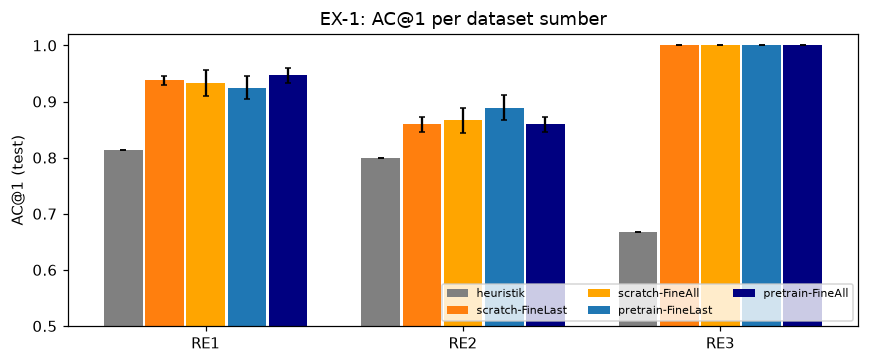

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.4))
models = ["heuristik", "scratch-FineLast", "scratch-FineAll", "pretrain-FineLast", "pretrain-FineAll"]
colors = ["grey", "C1", "orange", "C0", "navy"]
for j, S in enumerate(["RE1", "RE2", "RE3"]):
    for i, (m, c) in enumerate(zip(models, colors)):
        r = res[(res.source == S) & (res.model == m)].iloc[0]
        ax.bar(j + (i - 2) * 0.16, r.AC1_mean, 0.15, yerr=r.AC1_std, color=c, label=m if j == 0 else None, capsize=2)
ax.set_xticks(range(3), ["RE1", "RE2", "RE3"]); ax.set_ylim(0.5, 1.02); ax.set_ylabel("AC@1 (test)")
ax.legend(fontsize=7, ncol=3, loc="lower right"); ax.set_title("EX-1: AC@1 per dataset sumber"); plt.tight_layout()

## Selisih pretrain − scratch (kontribusi SSL)
Nilai positif berarti pre-training membantu. Satuannya poin AC@1. Untuk patokan, 1 kasus test setara 1.3 poin di RE1, 2.2 poin di RE2, dan 5.6 poin di RE3.

In [3]:
d = res.set_index(["source", "model"]).AC1_mean.unstack()
pd.DataFrame({"FineLast": d["pretrain-FineLast"] - d["scratch-FineLast"],
              "FineAll": d["pretrain-FineAll"] - d["scratch-FineAll"],
              "1 kasus test =": 1 / res.groupby("source").n_test.first()}).mul(100).round(1)

,FineLast,FineAll,1 kasus test =
source,,,
RE1,-1.3,1.3,1.3
RE2,3.0,-0.7,2.2
RE3,0.0,0.0,5.6


## Diagnostik: apakah model mendeteksi anomali atau menghafal service?

Root service di setiap sistem hanya 5 service yang sama (RE3: 2–4), dan service-service ini muncul di train maupun test. Model bisa saja hanya mengenali service yang sering menjadi root dari "sidik jari" perilaku normalnya. `scripts/diagnose_prior.py` menguji hal ini (encoder pretrain seed 0 + FineLast):

| Uji | Arti |
|---|---|
| prior frekuensi | ranking service menurut frekuensinya sebagai root di train, **tanpa melihat data** (seri diurai acak) |
| acak (1/N) | tebakan acak di antara N service |
| model, data normal | model pada data test asli |
| model, anomali dihapus | segmen pasca-injeksi diganti dengan data **pra-injeksi** dari kasus yang sama, sehingga tidak ada gangguan |

In [4]:
pd.read_csv(ROOT / "results" / "ex1" / "diagnose_prior.csv")

,source,uji,AC@1,AC@3,AC@5,Avg@5,n
0,RE1,prior frekuensi (tanpa data),0.200,0.600,1.000,0.600,75
1,RE1,acak (1/N),0.058,0.173,0.289,NaN,75
2,RE1,"model, data normal",0.907,0.987,1.000,0.965,75
3,RE1,"model, anomali dihapus",0.027,0.227,0.387,0.221,75
4,RE2,prior frekuensi (tanpa data),0.200,0.600,1.000,0.600,45
5,RE2,acak (1/N),0.057,0.172,0.287,NaN,45
6,RE2,"model, data normal",0.911,0.933,0.956,0.933,45
7,RE2,"model, anomali dihapus",0.089,0.267,0.444,0.262,45
8,RE3,prior frekuensi (tanpa data),0.500,1.000,1.000,0.878,18
9,RE3,acak (1/N),0.056,0.168,0.280,NaN,18


**Interpretasi diagnostik**
- Jika anomali dihapus, **AC@1 model jatuh ke 0.00–0.09**, setara tebakan acak. Artinya keputusan urutan pertama berasal dari anomali, bukan dari identitas service. AC@1 = 1.0 di RE3 adalah hasil asli, bukan kebocoran label.
- Pada data tanpa anomali, AC@3 dan AC@5 model masih sedikit di atas acak (misalnya RE3 AC@5 0.61 vs acak 0.28). Jadi untuk urutan berikutnya model ikut memakai sedikit informasi identitas service.
- **AC@3 dan AC@5 hampir tidak informatif di dataset ini.** Prior frekuensi tanpa data sudah mencapai AC@5 = 1.0 (RE1/RE2) dan AC@3 = 1.0 (RE3). Untuk laporan, **AC@1 adalah metrik utama**. AC@3/Avg@5 sebaiknya dilaporkan dengan catatan ini.

## Kesimpulan EX-1

1. **Fine-tuning dengan label jelas mengungguli heuristik.** Peningkatan AC@1 sekitar +0.06 sampai +0.13 di RE1/RE2, dan +0.33 di RE3. Peningkatan terbesar ada di fault jaringan (delay, loss) dan fault level kode (RE3), di mana besarnya penyimpangan saja tidak cukup.
2. **Pre-training TS2Vec tidak memberi keuntungan yang terukur di setting in-domain.** Selisih pretrain − scratch berada di −1.3 sampai +3.0 poin AC@1 (paling banyak 1–2 kasus test), tidak konsisten arahnya, dan masih dalam rentang variasi antar seed. Encoder CNN acak + head yang dilatih sudah menangkap perubahan perilaku setelah injeksi.
3. **Ceiling sudah dekat.** RE1 ±0.94, RE3 1.0. Masalah tersisa terkonsentrasi di fault **loss**, terutama di **Train Ticket**.
4. **Implikasi untuk penelitian:** kontribusi SSL perlu diuji di setting yang memang menjadi kekuatannya:
   - **EX-2 (transfer lintas dataset):** encoder dari S dipakai di T dengan distribusi berbeda;
   - **label sedikit:** fine-tuning dengan sebagian kecil kasus berlabel. Setting ini tidak ada di diagram pipeline, tetapi disarankan sebagai analisis pelengkap.
5. **Keterbatasan:** split test kecil (75 / 45 / 18). Untuk RE3 sebaiknya dipakai k-fold cross-validation, atau RE3 diperlakukan terutama sebagai target transfer.